# 퍼셉트론 & 딥러닝 기초 — 과제

INSIGHT 15기 · 심화 세션 2차

---

**안내**

- 수업 시간 실습에서는 **직접 돌려서 확인**했다면, 과제는 **직접 판단하고 골라 보는** 것이 목적입니다.
- `# 여기를 채우세요` 표시가 있는 칸을 채우거나, `**답:**` 아래에 본인의 생각을 적어주세요.
- 코드의 `None` 부분은 **`None`을 지우고** 적절한 숫자나 문자열로 바꾸세요. 채우기 전에는 해당 셀을 실행하지 마세요.
- 코드 문제는 **채우고 나면 실행이 됩니다.** 실행해서 결과가 맞는지 스스로 확인해 보세요.
- 서술 문제는 **정답 문장을 맞히는 게 아니라**, 왜 그렇게 생각했는지가 중요합니다. 짧아도 좋으니 이유를 적어주세요.

## 0. 환경 설정

제일 먼저 한 번만 실행해 주세요.

In [15]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec('tensorflow') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'tensorflow'])

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

try:                                   # 한글 폰트
    import koreanize_matplotlib
except ImportError:                    # 처음 한 번은 설치가 필요합니다
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "koreanize_matplotlib"])
    import koreanize_matplotlib

print("준비 완료")

준비 완료


---
# Part 1. 퍼셉트론과 논리 게이트

강의 `1장`에서 다룬 내용입니다.

## 문제 1. 가중치만 보고 무슨 게이트인지 맞히기

아래 네 개의 퍼셉트론이 있습니다. 각각 어떤 논리 게이트일까요?

**먼저 종이에 직접 계산해 보고**, 그다음 코드를 실행해 확인해 보세요.

In [16]:
def perceptron(x1, x2, w1, w2, b):
    return 1 if x1 * w1 + x2 * w2 + b > 0 else 0

INPUTS = [(0, 0), (0, 1), (1, 0), (1, 1)]

candidates = {
    "A": (1.0,  1.0, -1.5),
    "B": (-1.0, -1.0, 1.5),
    "C": (2.0,  2.0, -1.0),
    "D": (0.5,  0.5, -0.7),
}

for name, (w1, w2, b) in candidates.items():
    out = [perceptron(x1, x2, w1, w2, b) for x1, x2 in INPUTS]
    print(f"{name}: w1={w1:>5}, w2={w2:>5}, b={b:>5}  ->  출력 {out}")

A: w1=  1.0, w2=  1.0, b= -1.5  ->  출력 [0, 0, 0, 1]
B: w1= -1.0, w2= -1.0, b=  1.5  ->  출력 [1, 1, 1, 0]
C: w1=  2.0, w2=  2.0, b= -1.0  ->  출력 [0, 1, 1, 1]
D: w1=  0.5, w2=  0.5, b= -0.7  ->  출력 [0, 0, 0, 1]


**답:**

| 퍼셉트론 | 무슨 게이트인가 | 그렇게 판단한 이유 |
|---|---|---|
| A | AND | 계산했을 때 0, 0, 0, 1 로 둘 다 1일 때만 1이 나오는 and 게이트 |
| B | NAND | and 게아트와 출력이 정반대 |
| C | OR | 둘 중에 하나가 1이어도 1 |
| D | AND | 0, 0, 0, 1 |

> 추가 질문 — **A와 D는 출력이 완전히 같습니다.** 그런데 가중치는 다르죠.
> 같은 게이트를 만드는 가중치 조합이 여러 개인 이유는 무엇일까요?
>
> 결정 경계인 직선을 긋는 방법이 여러가지이기 떄문입니다

## 문제 2. NOR 게이트를 직접 설계하기

수업에서는 AND, OR, NAND를 다뤘습니다. 이번엔 **NOR**입니다.

NOR은 **둘 다 0일 때만 1**을 출력합니다.

| x1 | x2 | y |
|---|---|---|
| 0 | 0 | **1** |
| 0 | 1 | 0 |
| 1 | 0 | 0 |
| 1 | 1 | 0 |

`w1, w2, b`를 직접 정해서 `4/4`를 만들어 보세요.

In [17]:
NOR_ANSWER = [1, 0, 0, 0]

INPUTS = [(0, 0), (0, 1), (1, 0), (1, 1)]

def NOR(x1, x2):
    # 여기를 채우세요: None을 지우고 숫자를 입력하세요.
    w1, w2 = -2, -2
    b = 1
    return 1 if x1 * w1 + x2 * w2 + b > 0 else 0

correct = 0
for (x1, x2), ans in zip(INPUTS, NOR_ANSWER):
    out = NOR(x1, x2)
    correct += (out == ans)
    print(f"({x1}, {x2}) -> {out}   정답 {ans}   {'O' if out == ans else 'X'}")
print(f"=> {correct}/4")

(0, 0) -> 1   정답 1   O
(0, 1) -> 0   정답 0   O
(1, 0) -> 0   정답 0   O
(1, 1) -> 0   정답 0   O
=> 4/4


**답:**

> NOR는 OR와 어떤 관계인가요? 그 관계가 가중치에는 어떻게 나타났는지 설명해 주세요.
>
> NOR은 OR과 출력값이 반대인 게이트입니다. OR은 하나라도 1이라면 1, NOR는 모두 다 0이어야만 1  
**가중치, 편향이 부호가 반대로 뒤집힘!**

## 문제 3. XOR을 다층 퍼셉트론으로 해결하기

실습에서 **단층으로는 XOR이 불가능**하다는 걸 68,921개 조합으로 확인했습니다.

강의 `1-3`에서는 **게이트를 조합하면** 된다고 했죠. 직접 조합해 보세요.

먼저 아래 표의 빈칸을 **손으로 채워 보고**, 그다음 코드를 완성하시면 됩니다.

| x1 | x2 | s1 = NAND(x1,x2) | s2 = OR(x1,x2) | y = AND(s1,s2) | XOR 정답 |
|---|---|---|---|---|---|
| 0 | 0 | 1 | 0 | 0 | 0 |
| 0 | 1 | 1 | 1 | 1 | 1 |
| 1 | 0 | 1 | 1 | 1 | 1 |
| 1 | 1 | 0 | 1 | 0 | 0 |

In [18]:
def AND(x1, x2):  return perceptron(x1, x2,  0.5,  0.5, -0.7)
def OR(x1, x2):   return perceptron(x1, x2,  0.6,  0.6, -0.5)
def NAND(x1, x2): return perceptron(x1, x2, -0.5, -0.5,  0.7)

def XOR(x1, x2):
    # 여기를 채우세요: None을 지우고 위 세 게이트를 조합하세요.
    s1 = NAND(x1, x2)
    s2 = OR(x1, x2)
    return AND(s1, s2)

XOR_ANSWER = [0, 1, 1, 0]
print(" x1  x2 | s1  s2 |  y  | 정답")
print("--------|--------|-----|-----")
for (x1, x2), ans in zip(INPUTS, XOR_ANSWER):
    s1, s2, y = NAND(x1, x2), OR(x1, x2), XOR(x1, x2)
    print(f"  {x1}   {x2}  |  {s1}   {s2}  |  {y}  |  {ans}   {'O' if y == ans else 'X'}")

 x1  x2 | s1  s2 |  y  | 정답
--------|--------|-----|-----
  0   0  |  1   0  |  0  |  0   O
  0   1  |  1   1  |  1  |  1   O
  1   0  |  1   1  |  1  |  1   O
  1   1  |  0   1  |  0  |  0   O


**답:**

> 단층으로는 68,921개를 다 넣어도 안 되던 것이, 층을 하나 더 쌓으니 되었습니다.
> **층이 하나 늘어난 것이 무엇을 가능하게 만든 걸까요?** 실습 1의 산점도를 떠올리며 설명해 주세요.
>
> 층을 쌓으면 직선 여러 개를 동시에 그릴 수 있게 됩니다.

## 문제 4. 행렬 연산으로 표현하기

방금 만든 XOR은 게이트 함수를 세 번 호출했습니다.
실제 딥러닝은 이걸 **행렬 곱 한 번**으로 처리합니다.

$$\mathbf{a} = \mathbf{W}\mathbf{x} + \mathbf{b}$$

1층은 NAND와 OR **두 뉴런**을 동시에 계산합니다. 각 뉴런이 `W1`의 한 **행**이 됩니다.

In [19]:
def step(x):
    return (x > 0).astype(int)

def XOR_matrix(x1, x2):
    X = np.array([x1, x2])

    # 여기를 채우세요: None을 지우고 문제 3의 가중치·편향을 옮기세요.
    W1 = np.array([[-0.5, -0.5],      # 1행 = NAND 뉴런의 가중치
                   [0.6, 0.6]])     # 2행 = OR 뉴런의 가중치
    b1 = np.array([0.7, -0.5])       # [NAND 편향, OR 편향]

    W2 = np.array([0.5, 0.5])       # 2층 = AND 뉴런
    b2 = -0.7

    Z1 = step(W1 @ X + b1)            # -> [s1, s2]
    Z2 = step(W2 @ Z1 + b2)           # -> y
    return Z1, int(Z2)

for (x1, x2), ans in zip(INPUTS, XOR_ANSWER):
    (s1, s2), y = XOR_matrix(x1, x2)
    print(f"({x1}, {x2}) -> s1={s1}, s2={s2}, y={y}   정답 {ans}   {'O' if y == ans else 'X'}")

(0, 0) -> s1=1, s2=0, y=0   정답 0   O
(0, 1) -> s1=1, s2=1, y=1   정답 1   O
(1, 0) -> s1=1, s2=1, y=1   정답 1   O
(1, 1) -> s1=0, s2=1, y=0   정답 0   O


## 문제 5. 가중치를 사람이 아니라 **기계가** 찾게 하기

여기까지는 전부 **사람이 손으로** 가중치를 정했습니다.

| 문제 | 정해야 할 파라미터 |
|---|---|
| AND 게이트 | 3개 |
| 손글씨 분류 (28×28) | 수천 개 |
| GPT-3 | **1,750억 개** |

사람이 할 수 있는 규모가 아니죠. 그래서 **역전파**로 자동으로 찾습니다.

아래는 XOR을 역전파로 학습시키는 코드입니다.
**기울기를 구하는 두 줄**이 비어 있습니다. 강의 `2-1`의 연쇄법칙을 떠올려 채워보세요.

- 출력층 오차 신호 = (예측 − 정답) × (출력층 활성화 함수의 미분)
- 은닉층 오차 신호 = (출력층 오차 신호를 되돌려 받은 값) × (은닉층 활성화 함수의 미분)

In [20]:
def sigmoid(x):        return 1 / (1 + np.exp(-x))
def sigmoid_deriv(x):  s = sigmoid(x); return s * (1 - s)

X_train = np.array([[0,0],[0,1],[1,0],[1,1]], dtype=float)
y_train = np.array([[0],  [1],  [1],  [0]],   dtype=float)

np.random.seed(42)
W1 = np.random.randn(2, 4) * 0.5;  b1 = np.zeros((1, 4))
W2 = np.random.randn(4, 1) * 0.5;  b2 = np.zeros((1, 1))

lr, epochs = 50, 5000
loss_history = []

for epoch in range(epochs):
    z1 = X_train @ W1 + b1;  a1 = sigmoid(z1)          # 순전파
    z2 = a1 @ W2 + b2;       a2 = sigmoid(z2)

    loss = np.mean((a2 - y_train) ** 2)                # 손실 (MSE)
    loss_history.append(loss)

    # 여기를 채우세요: None을 지우고 역전파 식을 입력하세요.
    d2 = (a2 - y_train) * sigmoid_deriv(z2)
    d1 = (d2 @ W2.T) * sigmoid_deriv(z1)

    W2 -= lr * (a1.T @ d2);  b2 -= lr * d2.sum(axis=0, keepdims=True)
    W1 -= lr * (X_train.T @ d1);  b1 -= lr * d1.sum(axis=0, keepdims=True)

print(f"처음 손실 : {loss_history[0]:.6f}")
print(f"최종 손실 : {loss_history[-1]:.6f}\n")
for (x1, x2), pred, ans in zip(X_train.astype(int), a2.ravel(), y_train.ravel()):
    print(f"({x1}, {x2}) -> 예측 {pred:.4f}  (반올림 {round(pred)})   정답 {int(ans)}")

처음 손실 : 0.255675
최종 손실 : 0.500000

(0, 0) -> 예측 0.0000  (반올림 0)   정답 0
(0, 1) -> 예측 0.0000  (반올림 0)   정답 1
(1, 0) -> 예측 0.0000  (반올림 0)   정답 1
(1, 1) -> 예측 0.0004  (반올림 0)   정답 0


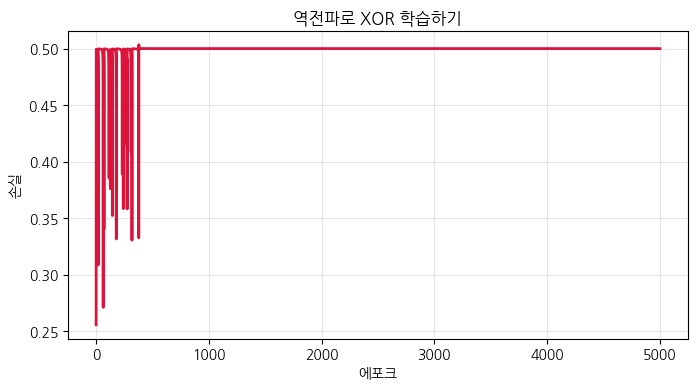

In [21]:
plt.figure(figsize=(8, 4))
plt.plot(loss_history, lw=2, color='crimson')
plt.xlabel('에포크'); plt.ylabel('손실')
plt.title('역전파로 XOR 학습하기'); plt.grid(alpha=0.3); plt.show()

**답:**

> 위 코드에서 `lr`을 **`0.05`로 줄이고** 다시 돌려보세요. 그다음 **`50.0`으로 키워서도** 돌려보세요.
> 각각 손실 그래프의 모양이 어떻게 달라지나요? 그리고 그 이유는 무엇일까요?
>

0.05
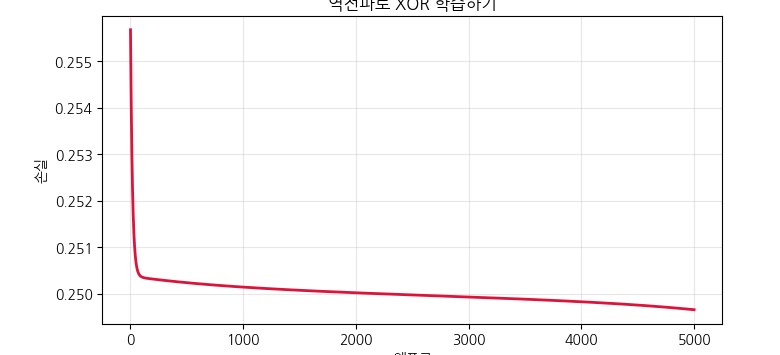

500
> (여기에 적어주세요)

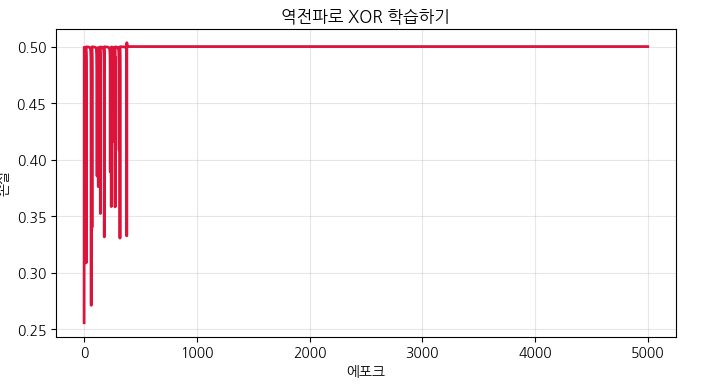

학습률을 작게 했을 때 손실 줄어드는 곡선이 완만해짐. 또, 에포크가 끝날 때까지 0에 도달하지 못
이유: 보폭이 너무 적으면 속도가 느려져서 완만해짐

학습률을 너무 크게 했을 때: 그래프가 이상해짐... 값이 발산해 버림
이유: 보폭이 너무 넓어서 손실이 줄어들지 못하고 학습 완전 실패

---
# Part 2. 딥러닝 모델은 어떻게 학습하는가

강의 `2장`에서 다룬 내용입니다.
여기서부터는 **직접 고르고 판단하는** 문제입니다.

## 문제 6. 손실 함수 고르기

아래 다섯 가지 상황에 알맞은 손실 함수를 `MSE` / `BCE` / `CEE` 중에서 고르고, **왜 그런지** 적어주세요.

강의 `2-2 ②`의 표를 참고하시되, **표를 그대로 베끼지 말고** 각 상황의 어떤 특징 때문에 그 손실 함수인지를 적어주세요.

**답:**

| 상황 | 손실 함수 | 이유 |
|---|---|---|
| 내일 서울의 최고 기온을 예측 | MSE | 기온은 연속형 데이터라서 회귀 문제이므로, 예측갑과 실제값의 차이를 제곱해서 평가해야 함 |
| 이메일이 스팸인지 아닌지 분류 | BCE | 이진 분류 문제이므로, 이진용 손실함수 사용 |
| 손글씨 사진을 0\~9 중 하나로 분류 | CEE | 0부터 9까지 10개의 클래스 중 단 하나를 맞히는 다중 분류 문제이므로 범주형 손실 함수 |
| 중고차 사진을 보고 가격을 예측 | mse | 연속형 데이터 맞추는 문제이므로 mse |
| 사진 속 동물이 개·고양이·새 중 무엇인지 분류 | cee | 3개 이상인 다중 분류이므로 범주형 손실함수 |

## 문제 7. 0.25는 어디서 나온 숫자인가

강의 `2-1 ③`에서 이런 식이 나왔습니다.

$$0.25 \times 0.25 \times 0.25 \times \cdots \approx 0$$

이 `0.25`가 **시그모이드 미분의 최댓값**이라고 했죠. 정말 그런지 직접 확인해 봅시다.

시그모이드 미분의 최댓값 : 0.250000
그때의 x 값              : 0.0000
  은닉층  2개를 지나면 : 0.25^2 = 0.0625000000
  은닉층  5개를 지나면 : 0.25^5 = 0.0009765625
  은닉층 10개를 지나면 : 0.25^10 = 0.0000009537


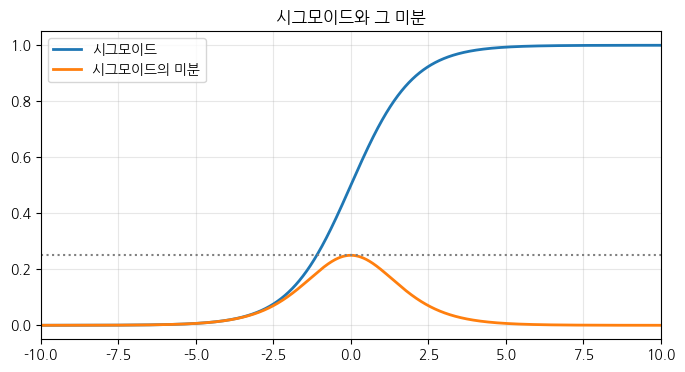

In [22]:
xs = np.linspace(-10, 10, 200001)
# 여기를 채우세요: None을 지우고 시그모이드 미분값을 구하세요.
grad = sigmoid_deriv(xs)

print(f"시그모이드 미분의 최댓값 : {grad.max():.6f}")
print(f"그때의 x 값              : {xs[grad.argmax()]:.4f}")

for n in [2, 5, 10]:
    print(f"  은닉층 {n:>2}개를 지나면 : 0.25^{n} = {0.25 ** n:.10f}")

plt.figure(figsize=(8, 4))
plt.plot(xs, sigmoid(xs), lw=2, label='시그모이드')
plt.plot(xs, grad, lw=2, label='시그모이드의 미분')
plt.axhline(0.25, ls=':', color='gray'); plt.xlim(-10, 10)
plt.legend(); plt.grid(alpha=0.3); plt.title('시그모이드와 그 미분'); plt.show()

**답:**

> (1) 미분값이 가장 큰 지점이 `x = 0` 입니다. 그래프를 보면 **양 끝으로 갈수록 미분값이 0에 가까워지죠.**
> 입력값이 아주 크거나 아주 작을 때 학습에 어떤 문제가 생길까요?
>입력값이 아주 크거나 작음 경우, 시그모이드 함수의 미분값이 0 에 가까워집니다. 역전파가 될 때 미분값들이 계속 곱해지는데 0에 가까운 값들이 계속 곱해지면 기울기 소실이 일어납니다.

> (2) ReLU는 양수 구간에서 미분값이 **항상 1**입니다.
> 1을 열 번 곱하면 1이고, 0.25를 열 번 곱하면 0.00000095입니다.
> **이 차이가 실제 학습에서 무엇을 바꾸는지** 설명해 주세요.
>
> 렐루는 양수구간에서 미분값이 항상 이므로 은닉층을 아무리 많이 지나가도 오차 깎임 없이 그대로 전달되어 학습이 원활합니다.
반면 시그모이드는 0.25를 계속 곱하게 되어 은닉층이 깊어지면 기울기가 0이 됩니다. 학습 불가!

## 문제 8. 배치 · 에포크 · 이터레이션

데이터가 **50,000개** 있습니다. 배치 크기를 **128**로 잡고 **10 에포크** 학습시키려고 합니다.

계산해서 채워보세요.

In [23]:
import math

N          = 50000
batch_size = 128
epochs     = 10

# 여기를 채우세요: None을 지우고 계산식을 입력하세요.
iterations_per_epoch = math.ceil(N / batch_size)
total_updates        = iterations_per_epoch * epochs

print(f"1 에포크당 이터레이션 수 : {iterations_per_epoch}")
print(f"전체 가중치 업데이트 횟수 : {total_updates}")

1 에포크당 이터레이션 수 : 391
전체 가중치 업데이트 횟수 : 3910


In [24]:
import math

N          = 50000
batch_size = 50000
epochs     = 10

# 여기를 채우세요: None을 지우고 계산식을 입력하세요.
iterations_per_epoch = math.ceil(N / batch_size)
total_updates        = iterations_per_epoch * epochs

print(f"1 에포크당 이터레이션 수 : {iterations_per_epoch}")
print(f"전체 가중치 업데이트 횟수 : {total_updates}")

1 에포크당 이터레이션 수 : 1
전체 가중치 업데이트 횟수 : 10


In [14]:
import math

N          = 50000
batch_size = 1
epochs     = 10

# 여기를 채우세요: None을 지우고 계산식을 입력하세요.
iterations_per_epoch = math.ceil(N / batch_size)
total_updates        = iterations_per_epoch * epochs

print(f"1 에포크당 이터레이션 수 : {iterations_per_epoch}")
print(f"전체 가중치 업데이트 횟수 : {total_updates}")

1 에포크당 이터레이션 수 : 50000
전체 가중치 업데이트 횟수 : 500000


**답:**

> 만약 배치 크기를 **50,000(전체)** 으로 바꾸면 업데이트 횟수는 몇 번이 될까요?
> 그리고 배치 크기를 **1**로 바꾸면요?
>
> 강의 `2-4 ④`에서 **미니 배치를 가장 많이 쓴다**고 했습니다. 위 두 극단과 비교해서 그 이유를 설명해 주세요.
>
> 배치 크기가 50000이 될 경우, 데이터가 너무 많아서 프로그램이 다운될 위험이 있을 것이고, 배치 사이즈를 1로 할 경우, 코드가 영원히 돌아갈 것입니다..
또, 배치를 5만으로 하면, 가중치 수정이 한 번 있게 되므로 학습 효율이 떨어지며, 배치를 1로 해서 쓰면 노이즈가 심하게 발생하게 될 것입니다.

## 문제 9. 손실 곡선만 보고 학습률 알아맞히기

**똑같은 모델**을 학습률만 바꿔 세 번 학습시켰습니다. 결과는 아래와 같습니다.

| | 1 에포크 | 10 에포크 | 50 에포크 | 100 에포크 | 최종 정확도 |
|---|---|---|---|---|---|
| **A** | 0.6907 | 0.6900 | 0.6869 | 0.6831 | 0.580 |
| **B** | 4.2903 | 1.9707 | 1.9707 | 1.9707 | 0.538 |
| **C** | 0.6594 | 0.3655 | 0.2541 | 0.2010 | 0.918 |

이 중 하나는 학습률이 **`0.0001`**, 하나는 **`0.1`**, 하나는 **`20.0`** 이었습니다.

> 참고 — 이건 **이진 분류** 문제입니다. 아무것도 학습하지 않고 찍으면 정확도가 약 `0.5`가 나옵니다.

**답:**

| | 학습률 | 그렇게 판단한 이유 |
|---|---|---|
| A | 0.0001 | 학습률(보폭)이 너무 작아서 손실이 제자리걸음 |
| B | 20.0 | 보폭이 너무 커서 손실이 발산해버린 상 |
| C | 0.1 | 중도값이고, 손실이 안정적으로 줄어들어서 학습이 가장 잘 이루어짐! |

> 추가 질문 — **B는 10 에포크 이후로 손실이 `1.9707`에서 소수점까지 똑같습니다.**
> 줄어들지도, 늘어나지도 않아요. 모델에 무슨 일이 일어난 걸까요?
> 학습률이 너무 커서 발산해버렸기 때문입니다. 기울기가 0이 되어 역전파가 더 이상 일어나지 않고 학습을 멈춘 상황!

> 근데 처음에 B가 0.0001인 줄 알았어요...... 어려워서 AI 힘을 빌려 답변 완성했습니다. 원래는 이렇게 썼어요) 학습률이 너무 작아서 손실 곡선이 엄청나게 완만해진 상태 같습니다. (위에 XOR 게이트 손실 그래프처럼)

## 문제 10. 옵티마이저 고르기

실습에서 SGD · 모멘텀 · Adam의 수렴 속도를 비교해 봤습니다.

아래 상황에서는 어떤 옵티마이저를 고르시겠어요?

**답:**

| 상황 | 고른 옵티마이저 | 이유 |
|---|---|---|
| 처음 만들어보는 모델이라 뭘 써야 할지 모르겠다 | 아담 | 잘 모를 땐 무조건 아담을 쓰라고 했음... |
| 손실이 계속 좌우로 튀면서 잘 안 내려간다 | 모멘텀 | 관성을 이용해 노이즈를 깎아주기 때문 |
| 파라미터마다 기울기 크기 차이가 아주 크다 | RMSProp | 학습률을 보정해줘서 모든 파라미터가 균형 있게 학습되도록 하기 때문! |

> 추가 질문 — **Adam은 모멘텀과 RMSProp을 합친 것**이라고 배웠습니다.
> 그렇다면 **Adam이 있는데도 모멘텀과 RMSProp을 따로 배우는 이유**는 뭘까요?
>
> 아담은 모멘텀과 rmsprop을 합친 것이지만, 모멘텀과 rmsprop이 각각 어떤 효과를 주는지 알아야 더 잘 알고 사용할 수 있기 때문입니다!

## 문제 11. 상황을 읽고 모델을 직접 짜기

> **상황**
> 꽃 사진에서 뽑아낸 **특성 64개**를 입력받아,
> 그 꽃이 **장미 · 튤립 · 해바라기 · 백합 · 국화** 중 무엇인지 맞히는 모델을 만들려고 합니다.
> 데이터는 **12,000장**이고, 한 번에 **64장씩** 묶어서 **30번** 반복 학습시킬 예정입니다.

이 상황에 맞게 코드를 완성하세요. **강의 `2-6`의 코드 세 덩어리 구조 그대로**입니다.

In [25]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

# ① 모델 구조
model = Sequential()
model.add(Input((64,)))                        # None을 지우고 입력 특성 수를 쓰세요.
model.add(Dense(32, activation='relu'))          # 따옴표 안 None만 지우고 은닉층 활성화 함수를 쓰세요.
model.add(Dense(5, activation='softmax'))        # 각 None을 지우고 출력 수와 활성화 함수를 쓰세요.

# ② 학습 방법 설정
model.compile(optimizer='adam',                  # 따옴표 안 None만 지우고 옵티마이저를 쓰세요.
              loss='categorical_crossentropy',                       # 따옴표 안 None만 지우고 손실 함수를 쓰세요.
              metrics=['acc'])

model.summary()

# 가짜 데이터로 30 에포크 학습까지 실행되는지 확인합니다.
X_fake = np.random.randn(12000, 64)
y_fake = tf.keras.utils.to_categorical(np.random.randint(0, 5, 12000), 5)

# ③ 학습 실행
model.fit(X_fake, y_fake, batch_size=64, epochs=30, verbose=1)   # 각 None을 지우고 값을 쓰세요.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,245 (8.77 KB)

 Trainable params: 2,245 (8.77 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - acc: 0.2018 - loss: 1.7545
Epoch 2/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.2131 - loss: 1.6460
Epoch 3/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.2295 - loss: 1.6189
Epoch 4/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.2397 - loss: 1.6057
Epoch 5/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - acc: 0.2514 - loss: 1.5965
Epoch 6/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.2558 - loss: 1.5900
Epoch 7/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - acc: 0.2678 - loss: 1.5840
Epoch 8/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.2690 - loss: 1.5790
Epoch 9/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - acc: 0.2733 - loss: 1.5750
Epoch 10/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - acc: 0.2827 - loss: 1.5709
Epoch 11/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.2847 - loss: 1.5666
Epoch 12/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.2887 - loss: 1.5634
Epoch 13/30
188/188 ━━━━━

**답:**

> 위에서 고른 `loss`와 출력층 `activation`을, **왜 그것으로 골랐는지** 상황의 어떤 부분을 근거로 삼았는지 적어주세요.

> 다중 분류 문제이므로, 각 클래스별 확률을 계산하려면 활성화함수는 softmax를 쓰고, 그에맞는 다중분류용 손실함수 categorical_crossentropy 를 골랐습니다.

> 그리고 실행 결과에 찍힌 **`188/188`** 이라는 숫자는 무엇을 뜻할까요? (문제 8을 떠올려 보세요)

> 이터레이션 수 입니다. 12000 / 62 = 약 188 !
>

## 문제 12. 잘못된 코드 찾아 고치기

아래 세 코드는 **각각 상황에 맞지 않는 부분이 있습니다.**
무엇이 잘못됐는지 찾고, 어떻게 고쳐야 하는지 적어주세요.

> 이 코드들은 **실행하지 않아도 됩니다.** 눈으로 읽고 판단하는 문제입니다.

In [ ]:
# ---------- (a) 아파트 가격(억 원)을 예측하는 모델 ----------
model_a = Sequential()
model_a.add(Input((15,)))
model_a.add(Dense(32, activation='relu'))
model_a.add(Dense(1, activation='sigmoid'))
model_a.compile(optimizer='adam', loss='binary_crossentropy')


# ---------- (b) 이메일이 스팸인지 아닌지 판별하는 모델 ----------
model_b = Sequential()
model_b.add(Input((100,)))
model_b.add(Dense(64, activation='relu'))
model_b.add(Dense(1, activation='sigmoid'))
model_b.compile(optimizer='adam', loss='categorical_crossentropy')


# ---------- (c) 손글씨 숫자(0~9)를 분류하는 모델 ----------
model_c = Sequential()
model_c.add(Input((784,)))
model_c.add(Dense(128, activation='softmax'))
model_c.add(Dense(64,  activation='softmax'))
model_c.add(Dense(10,  activation='softmax'))
model_c.compile(optimizer='adam', loss='categorical_crossentropy')

print("코드 셀입니다. 실행하지 않고 읽어보세요.")

**답:**

| | 무엇이 잘못됐나 | 어떻게 고쳐야 하나 | 왜 |
|---|---|---|---|
| (a) | 회귀인데 시그모이드를 씀, 이진분류용인 binary 씀 | 회귀 출력층은 활성하 함수 X,손실 함수는 mse써야 합니다! |  |
| (b) | 이진분류 문제인데 손실함수를 잘못 사용 | binary_crossentropy 써야 함! |  |
| (c) | 다중분류 문제랑 categorical은 맞췄는데 은닉층마다 다 softmax 씀 | softmax는 최종 출력층에서만 써야 함! |  |

> 추가 질문 — 세 코드 중 **(c)는 그래도 학습이 되긴 합니다.** 다만 성능이 나쁘죠.
> 나머지 둘과 비교했을 때 (c)의 문제는 성격이 어떻게 다른가요?
>
> a와 b는 다 틀리게 사용했는데, c는 다중 분류 문제에 맞는 categorical은 맞게 사용했습니다.

---
## 마지막으로

> 오늘 강의의 첫 화면에 이런 질문이 있었습니다.
>
> **"모델을 짤 때 내가 정해야 하는 게 뭘까요? 그리고 뭘 기준으로 정하나요?"**
>
> 과제를 다 푼 지금, 이 질문에 **본인의 문장으로** 답해 주세요.
>
> 우선 하이퍼파라미터들을 정해야 하는데, 활성화 함수, 배치, 에포크, 최적화 함수 등을 정해야 합니다. 이진/다중분류, 회귀인지도 따져봐야 하고, 컴퓨터 메모리나 과적합 위험성 등을 고려해서 정하면 됩니다.
---

### 수고하셨습니다